# Santali vocabulary extension at a larger scale (unified run)

**Question.** The 95-token whole-word extension (frequency threshold 50, mean initialisation) showed **no measurable gain** over a baseline trained with the same procedure (baseline v2: test BLEU 12.32 / chrF 45.26; 95-token extended: 12.40 / 45.64; paired-bootstrap intervals include zero). Those 95 tokens change only about 2% of target tokens. This notebook tests whether **adding many more tokens** (a larger "dose") changes translation quality.

**One run = one configuration.** Set `MIN_FREQ` (and optionally `INIT`, `SEED`) in Section 2 and run the notebook. Default: `MIN_FREQ = 10` (about 1,220 new tokens, about 7.4% fewer target tokens), mean initialisation, seed 42. The training loop, hyperparameters, data order, evaluation pipeline and decoder are identical for every configuration, so runs are directly comparable with baseline v2 and with each other.

| `MIN_FREQ` | New tokens | Held-out token reduction |
|---:|---:|---:|
| 100 | 21 | 0.74% |
| 50 | 95 | 1.89% |
| 20 | 445 | 4.73% |
| 10 | 1,220 | 7.36% |
| 5 | 3,020 | 10.17% |

**Training is identical to baseline v2:** LoRA r=16 / alpha=32 / dropout 0.05 on `q_proj` and `v_proj`; batch 4 x accumulation 4; AdamW, learning rate 1e-4, weight decay 0.01; 3% warmup then linear decay; fp16 autocast + GradScaler with non-finite-gradient skipping; clipping at 1.0; patience 2, minimum delta 0.001; seed 42; 10 planned epochs. **The only differences are the added vocabulary rows (trained in fp32) and the extension-aware labels.**

## Inputs and settings required before running
| Item | Required | Notes |
|---|---|---|
| Notebook setting **Internet = On** | yes | pip install and model download |
| Notebook setting **Accelerator = GPU T4** | yes | one GPU is used |
| Kaggle secret **`HF_TOKEN`** (Add-ons > Secrets) | yes | your Hugging Face token |
| Dataset **Common Tribal Preprocessing** (`splits/santali_*.parquet`) | yes | same as before |
| Dataset with **baseline v2 predictions**: `new_baseline_v2_test.csv` and `new_baseline_v2_val300.csv` (inside `baseline_v2_scaled/predictions/` of your baseline results zip) | yes, for Section 13 | training runs without it, but the comparison needs it |
| Dataset with the **95-token extended predictions** `extended_fixed_test.csv` | optional | adds a second reference row to the comparison |
| Backup zip from an earlier session of THIS run (folder named like `ext_f10_mean_s42`) | only when resuming | attach it as a dataset; training resumes automatically |

**Run order:** run Section 1 cell 1 (install), then **restart the session**, then run everything from Section 1 cell 2 onward. Do not rerun the install cell after the restart.

**Time:** about 15 to 17 minutes per epoch (about 2.5 to 3 hours for 10 epochs) plus about 25 minutes for evaluation.

## Section 1. Environment
Install the pinned packages and remove the incompatible preinstalled `torchao`. Restart the session after the install cell. Keep the printed versions from cell 1.2: `peft`, `torch` and `accelerate` are not pinned, so they belong in your methods description.

In [ ]:
# Section 1.1: install pinned dependencies (run ONCE, then restart the session)
%pip install -q --no-cache-dir \
    "transformers==4.46.3" \
    "tokenizers==0.20.3" \
    "IndicTransToolkit==1.1.1" \
    peft accelerate sacrebleu sentencepiece kagglehub

# Kaggle ships an old torchao that newer peft versions reject. This notebook does not use torchao.
%pip uninstall -y torchao

In [1]:
# Section 1.2: verify packages and GPU (run after the restart)
import sys
import importlib.metadata as metadata
import torch

print("=== Package versions ===")
for package in ["transformers", "tokenizers", "IndicTransToolkit", "torch", "peft", "accelerate", "sacrebleu", "sentencepiece", "torchao"]:
    try:
        print(f"{package:20s}: {metadata.version(package)}")
    except metadata.PackageNotFoundError:
        print(f"{package:20s}: NOT INSTALLED")

print("\nPython:", sys.version.split()[0])
assert torch.cuda.is_available(), "No GPU. Set Accelerator to GPU T4 and restart the session."
print("GPU:", torch.cuda.get_device_name(0))
print("GPU memory (GiB): %.1f" % (torch.cuda.get_device_properties(0).total_memory / 1024**3))

import transformers
assert transformers.__version__ == "4.46.3", "transformers is not 4.46.3: rerun the install cell and restart the session."

=== Package versions ===
transformers        : 4.46.3
tokenizers          : 0.20.3
IndicTransToolkit   : 1.1.1
torch               : 2.11.0+cu128
peft                : 0.20.0
accelerate          : 1.14.0
sacrebleu           : 2.6.0
sentencepiece       : 0.2.2
torchao             : NOT INSTALLED

Python: 3.13.15
GPU: Tesla T4
GPU memory (GiB): 14.6


## Section 2. Authentication and run configuration
**This is the only section you edit between runs.** `MIN_FREQ` sets the vocabulary size, `INIT` the initialisation of the new rows (`"mean"` of the constituent pieces, as in the earlier extended run, or `"random"`), and `SEED` the seed.

In [2]:
# Section 2.1: imports, Hugging Face login, configuration
import gc, glob, json, math, os, random, re, shutil, time, unicodedata, warnings
from collections import Counter
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.optim.lr_scheduler import LambdaLR
from kaggle_secrets import UserSecretsClient
from huggingface_hub import login

warnings.filterwarnings("ignore")

hf_token = UserSecretsClient().get_secret("HF_TOKEN")
login(token=hf_token)
print("Hugging Face authentication complete.")

# ---------------- EDIT THESE ----------------
MIN_FREQ = 20        # 100 -> 21 tokens, 50 -> 95, 20 -> 445, 10 -> 1220, 5 -> 3020
INIT = "random"        # "mean" (as in the earlier extended run) or "random"
SEED = 42
# --------------------------------------------

DEVICE = torch.device("cuda")
MODEL_ID = "ai4bharat/indictrans2-indic-indic-1B"
SRC_LANG, TGT_LANG = "eng_Latn", "sat_Olck"

# Training configuration (identical to baseline v2)
BATCH_SIZE, GRAD_ACCUM = 4, 4
NUM_EPOCHS = 10
LEARNING_RATE, WEIGHT_DECAY = 1e-4, 0.01
WARMUP_RATIO, MAX_GRAD_NORM = 0.03, 1.0
PATIENCE, MIN_DELTA = 2, 0.001
MAX_LEN = 256
MAX_EPOCHS_THIS_SESSION = NUM_EPOCHS      # lower this to stop cleanly after N epochs and resume later

EXPECTED_NEW_TOKENS = {100: 21, 50: 95, 20: 445, 10: 1220, 5: 3020}
RUN_NAME = f"ext_f{MIN_FREQ}_{INIT}_s{SEED}"
RUN_DIR = Path("/kaggle/working") / RUN_NAME
RUN_DIR.mkdir(parents=True, exist_ok=True)
PRED_DIR = RUN_DIR / "predictions"; PRED_DIR.mkdir(exist_ok=True)

def seed_everything(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

seed_everything(SEED)
assert INIT in ("mean", "random")
print("Run:", RUN_NAME, "| output folder:", RUN_DIR)

Hugging Face authentication complete.
Run: ext_f20_random_s42 | output folder: /kaggle/working/ext_f20_random_s42


## Section 3. Data
Load the frozen Santali splits from the attached **Common Tribal Preprocessing** dataset. Sizes must match the earlier experiments exactly (17,883 / 993 / 994).

In [3]:
# Section 3.1: locate and load the Santali splits
INPUT_ROOT = Path("/kaggle/input")
print("Top-level input folders:")
for p in sorted(INPUT_ROOT.iterdir()):
    print(" -", p.name)

matches = [p for p in INPUT_ROOT.rglob("santali_train.parquet") if p.parent.name == "splits"]
assert len(matches) == 1, f"Expected one splits/santali_train.parquet, found {len(matches)}. Attach the Common Tribal Preprocessing dataset."
SPLIT_DIR = matches[0].parent

SRC_COL, TGT_COL = "English", "Santali"
train_df = pd.read_parquet(SPLIT_DIR / "santali_train.parquet")
val_df   = pd.read_parquet(SPLIT_DIR / "santali_validation.parquet")
test_df  = pd.read_parquet(SPLIT_DIR / "santali_test.parquet")

for name, df in [("train", train_df), ("validation", val_df), ("test", test_df)]:
    assert {SRC_COL, TGT_COL} <= set(df.columns), f"{name}: missing columns"
    assert df[[SRC_COL, TGT_COL]].notna().all().all(), f"{name}: missing values"
    print(f"{name:11s}: {len(df):6d} rows")
assert (len(train_df), len(val_df), len(test_df)) == (17883, 993, 994), "Split sizes differ from the earlier experiments."
print("PASS: splits match the earlier experiments.")

Top-level input folders:
 - datasets
train      :  17883 rows
validation :    993 rows
test       :    994 rows
PASS: splits match the earlier experiments.


## Section 4. Tokenizer and source preprocessor
The tokenizer is IndicTrans2's own and stays unchanged; the extension is applied to the **target labels** and the decoder's output layers. `IndicProcessor` normalises the English source, as in all earlier runs.

In [4]:
# Section 4.1: tokenizer and IndicProcessor
from transformers import AutoTokenizer
from IndicTransToolkit import IndicProcessor

tok = AutoTokenizer.from_pretrained(MODEL_ID, trust_remote_code=True, token=hf_token)
processor = IndicProcessor(inference=True)

sp = tok.tgt_spm
BASE_TARGET_VOCAB_SIZE = len(tok.tgt_encoder)
EOS_ID, PAD_ID, DEC_START_ID, UNK_ID = 2, 1, 2, 3
print("Tokenizer:", type(tok).__name__, "| source vocab:", tok.src_vocab_size, "| target vocab:", tok.tgt_vocab_size)
assert (tok.src_vocab_size, tok.tgt_vocab_size) == (122706, 122672)
assert BASE_TARGET_VOCAB_SIZE == 122672
assert (tok.eos_token_id, tok.pad_token_id) == (EOS_ID, PAD_ID)

tokenizer_config.json: 0.00B [00:00, ?B/s]

tokenization_indictrans.py: 0.00B [00:00, ?B/s]

A new version of the following files was downloaded from https://huggingface.co/ai4bharat/indictrans2-indic-indic-1B:
- tokenization_indictrans.py
. Make sure to double-check they do not contain any added malicious code. To avoid downloading new versions of the code file, you can pin a revision.


dict.SRC.json: 0.00B [00:00, ?B/s]

dict.TGT.json: 0.00B [00:00, ?B/s]

model.SRC:   0%|          | 0.00/3.26M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/96.0 [00:00<?, ?B/s]

Tokenizer: IndicTransTokenizer | source vocab: 122706 | target vocab: 122672


## Section 5. Candidate words for this run
Candidates are whole whitespace-delimited training words that occur at least `MIN_FREQ` times, contain no punctuation or symbols, and split into more than one SentencePiece piece. They are ordered by frequency (then piece saving, then spelling), exactly as in the earlier 95-token run, so IDs from 122,672 upward are assigned in that order. A reproduction check follows: the counts must match the earlier audit.

In [5]:
# Section 5.1: build the candidate pool from the TRAINING split only and select this run's words
train_texts_full = train_df[TGT_COL].dropna().astype(str).tolist()
word_counts = Counter()
for t in train_texts_full:
    word_counts.update(t.split())
print("Unique whitespace words in training:", len(word_counts), "(earlier audit: 41757)")

def _only_punct(w): return all(unicodedata.category(c)[0] in {"P", "S"} for c in w)
def _word_only(w): return bool(w) and all(unicodedata.category(c)[0] not in {"P", "S"} for c in w)

rows = []
for w, f in word_counts.items():
    if f < 5 or _only_punct(w):
        continue
    pieces = sp.encode(w, out_type=str)
    if len(pieces) > 1:
        rows.append({"word": w, "frequency": f, "piece_count": len(pieces),
                     "potential_piece_reduction": len(pieces) - 1})
clean_candidates = pd.DataFrame(rows)
clean_candidates = clean_candidates[clean_candidates["word"].map(_word_only)].copy()

def select_candidates(min_freq):
    sub = clean_candidates[(clean_candidates["frequency"] >= min_freq) & (clean_candidates["piece_count"] > 1)]
    sub = (sub.drop_duplicates(subset=["word"])
              .sort_values(["frequency", "potential_piece_reduction", "word"], ascending=[False, False, True], kind="stable")
              .reset_index(drop=True))
    existing = set(tok.tgt_encoder.keys())
    return sub[~sub["word"].isin(existing)].reset_index(drop=True)

check = [{"min_freq": k, "expected_new": v, "rebuilt_new": len(select_candidates(k)), "match": len(select_candidates(k)) == v}
         for k, v in EXPECTED_NEW_TOKENS.items()]
display(pd.DataFrame(check))

new_df = select_candidates(MIN_FREQ)
new_words = new_df["word"].tolist()
if MIN_FREQ in EXPECTED_NEW_TOKENS:
    assert len(new_words) == EXPECTED_NEW_TOKENS[MIN_FREQ], "Candidate count differs from the earlier audit: check the dataset version."
N_NEW = len(new_words)
EXTENDED_VOCAB_SIZE = BASE_TARGET_VOCAB_SIZE + N_NEW
candidate_to_id = {w: BASE_TARGET_VOCAB_SIZE + i for i, w in enumerate(new_words)}
id_to_candidate = {v: k for k, v in candidate_to_id.items()}
print(f"\nThis run adds {N_NEW} tokens (IDs {BASE_TARGET_VOCAB_SIZE} to {EXTENDED_VOCAB_SIZE - 1}); rarest training frequency: {int(new_df['frequency'].min())}")
print("First 10 words:", new_words[:10])
if MIN_FREQ == 50:
    assert new_words[:3] == ["ᱤᱧᱟᱹᱜ", "ᱤᱧᱤᱧ", "ᱩᱱᱫᱚ"], "Order differs from the earlier 95-token run."

Unique whitespace words in training: 41757 (earlier audit: 41757)


,min_freq,expected_new,rebuilt_new,match
0,100,21,21,True
1,50,95,95,True
2,20,445,445,True
3,10,1220,1220,True
4,5,3020,3020,True



This run adds 445 tokens (IDs 122672 to 123116); rarest training frequency: 20
First 10 words: ['ᱤᱧᱟᱹᱜ', 'ᱤᱧᱤᱧ', 'ᱩᱱᱫᱚ', 'ᱫᱳᱠᱟᱱ', 'ᱢᱩᱜᱷᱚᱞ', 'ᱱᱩᱱᱟᱹᱜ', 'ᱟᱞᱮᱭᱟᱜ', 'ᱤᱧᱨᱮᱱ', 'ᱟᱹᱲᱤᱥ', 'ᱦᱟᱦᱟᱲᱟᱜ']


## Section 6. Extension-aware label encoder and decoder
**Encoder.** A candidate word is replaced by its new ID only when it starts the text or follows whitespace and ends the text or precedes whitespace or listed punctuation; the text between matches goes through the original tokenizer (the rule used in the earlier 95-token run). **Decoder.** Generated IDs are decoded with the tokenizer's standard decoding for ordinary pieces; each added word is inserted as a whole word with a space before it, and no space before a word-continuation piece or closing punctuation. The checks below must pass before any training starts.

**Note on missing pieces.** A few candidate words may contain a SentencePiece piece that is absent from the model's target vocabulary; the original tokenizer turns such a piece into `<unk>`, which is silently dropped when decoding. The extension keeps those words whole, so for them the extension also recovers text that the baseline loses. The notebook counts these words (Section 6.3) so that this effect can be separated from the effect of fewer tokens.

In [6]:
# Section 6.1: encoder and decoder
def encode_original_target_segment(segment):
    if not segment:
        return []
    with tok.as_target_tokenizer():
        return tok.convert_tokens_to_ids(tok.tokenize(segment))

_ordered = sorted(new_words, key=lambda w: (-len(w), w))
added_pattern = re.compile(r"(?<!\S)(" + "|".join(re.escape(w) for w in _ordered) + r")(?=$|[\s\.,!?;:()\[\]{}\"'।॥])")

def ext_encode(text, add_eos=False):
    ids, cursor = [], 0
    for m in added_pattern.finditer(text):
        ids.extend(encode_original_target_segment(text[cursor:m.start()]))
        ids.append(candidate_to_id[m.group(1)])
        cursor = m.end()
    ids.extend(encode_original_target_segment(text[cursor:]))
    if add_eos and (not ids or ids[-1] != EOS_ID):
        ids.append(EOS_ID)
    return ids

CLOSERS = set(".,!?;:)]}।॥")
id_to_piece = {v: k for k, v in tok.tgt_encoder.items()}
special_ids = set(tok.all_special_ids)

def decode_generated(token_ids):
    ids = [int(x) for x in token_ids]
    if ids and ids[0] == DEC_START_ID:
        ids = ids[1:]
    clean = []
    for t in ids:
        if t == EOS_ID:
            break
        if t == PAD_ID:
            continue
        clean.append(t)
    parts, seg = [], []
    def flush():
        if seg:
            first = next((t for t in seg if t not in special_ids), None)
            text = tok.decode(seg, skip_special_tokens=True, clean_up_tokenization_spaces=True).strip()
            if text:
                continuation = first is not None and not id_to_piece.get(first, "").startswith("\u2581")
                parts.append(("seg", text, continuation))
            seg.clear()
    for t in clean:
        if t >= BASE_TARGET_VOCAB_SIZE:
            flush(); parts.append(("ext", id_to_candidate[t], False))
        else:
            seg.append(t)
    flush()
    out, prev_kind = "", None
    for kind, text, continuation in parts:
        if not out:
            out = text
        elif kind == "seg" and (text[0] in CLOSERS or (prev_kind == "ext" and continuation)):
            out += text
        else:
            out += " " + text
        prev_kind = kind
    return out.strip()
print("Encoder and decoder defined.")

Encoder and decoder defined.


In [7]:
# Section 6.2: integrity checks before any training
val_texts = val_df[TGT_COL].astype(str).str.strip().tolist()

# (a) text with no added word must encode exactly like the original tokenizer
checked = mismatch = 0
for t in val_texts:
    if added_pattern.search(t) is None:
        checked += 1
        mismatch += (ext_encode(t) != encode_original_target_segment(t))
print(f"(a) unchanged-text check: {checked} sentences without added words, {mismatch} mismatches (must be 0)")
assert mismatch == 0

# (b) decoding the extended encoding must equal decoding the original encoding (checks the spacing rules).
# Exception: an added word that contains a piece MISSING from the model vocabulary is lost (<unk>) by the original
# tokenizer but kept whole by the extension, so sentences containing such a word are excluded from this equality check.
def has_missing_piece(w):
    return any(sp.IdToPiece(i) not in tok.tgt_encoder for i in sp.EncodeAsIds(w))
words_with_missing_piece = {w for w in new_words if has_missing_piece(w)}
print(f"Added words containing a piece missing from the model vocabulary: {len(words_with_missing_piece)} of {N_NEW}")

test_texts_ref = test_df[TGT_COL].astype(str).str.strip().tolist()
diff = compared = skipped = 0
for t in test_texts_ref[:300] + val_texts[:300]:
    if any(m.group(1) in words_with_missing_piece for m in added_pattern.finditer(t)):
        skipped += 1
        continue
    compared += 1
    a = tok.decode(encode_original_target_segment(t), skip_special_tokens=True, clean_up_tokenization_spaces=True).strip()
    b = decode_generated([DEC_START_ID] + ext_encode(t) + [EOS_ID])
    diff += (a != b)
print(f"(b) decoder check: {compared} references compared, {diff} differ from the original decoding (expected 0); "
      f"{skipped} skipped because they contain an added word with a missing piece")
assert diff == 0, "The decoder does not reproduce the original decoding: stop and inspect."
print("PASS: encoder and decoder are consistent.")

(a) unchanged-text check: 428 sentences without added words, 0 mismatches (must be 0)
Added words containing a piece missing from the model vocabulary: 0 of 445
(b) decoder check: 600 references compared, 0 differ from the original decoding (expected 0); 0 skipped because they contain an added word with a missing piece
PASS: encoder and decoder are consistent.


In [8]:
# Section 6.3: tokenization statistics for this vocabulary (CPU; compare with the earlier audit table)
sample = train_texts_full[:2000]
words_sample = sum(len(t.split()) for t in sample)
orig_tok_sample = sum(len(encode_original_target_segment(t)) for t in sample)
ext_ids_sample = [ext_encode(t) for t in sample]
ext_tok_sample = sum(len(x) for x in ext_ids_sample)
val_orig = sum(len(encode_original_target_segment(t)) for t in val_texts)
val_ext_ids = [ext_encode(t) for t in val_texts]
val_ext = sum(len(x) for x in val_ext_ids)
val_used = Counter(i for ids in val_ext_ids for i in ids if i >= BASE_TARGET_VOCAB_SIZE)

stats = {
    "train_sample_fertility_original": round(orig_tok_sample / words_sample, 4),
    "train_sample_fertility_extended": round(ext_tok_sample / words_sample, 4),
    "train_sample_token_reduction_%": round(100 * (orig_tok_sample - ext_tok_sample) / orig_tok_sample, 2),
    "val_token_reduction_%": round(100 * (val_orig - val_ext) / val_orig, 2),
    "val_new_token_share_%": round(100 * sum(val_used.values()) / val_ext, 2),
    "new_tokens_unused_in_val": N_NEW - len(val_used),
    "rarest_training_frequency": int(new_df["frequency"].min()),
}
# added words that contain a piece missing from the model vocabulary (the original tokenizer turns that piece into <unk>)
stats["candidate_words_with_a_piece_missing_from_model_vocab"] = len(words_with_missing_piece)
display(pd.Series(stats).to_frame("value"))
json.dump(stats, open(RUN_DIR / "tokenization_stats.json", "w"), indent=2)

,value
train_sample_fertility_original,1.4421
train_sample_fertility_extended,1.3719
train_sample_token_reduction_%,4.8700
val_token_reduction_%,4.7300
val_new_token_share_%,3.8900
new_tokens_unused_in_val,79.0000
rarest_training_frequency,20.0000
candidate_words_with_a_piece_missing_from_model_vocab,0.0000


## Section 7. Training examples, collator and loaders
Sources are preprocessed with `IndicProcessor` (as in all earlier runs). Labels use the extension-aware encoder with EOS appended once, truncated to 256 with EOS kept, padding masked as -100. The training loader uses a generator seeded with `SEED + epoch`, so the data order is reproducible and survives a resume.

In [9]:
# Section 7.1: examples (preprocessing ~18k sources takes a minute or two)
def prepare_examples(df):
    out = []
    for _, row in df.iterrows():
        s, t = str(row[SRC_COL]).strip(), str(row[TGT_COL]).strip()
        if not s or not t:
            continue
        out.append({"source": processor.preprocess_batch([s], src_lang=SRC_LANG, tgt_lang=TGT_LANG)[0], "target": t})
    return out

train_examples = prepare_examples(train_df)
val_examples = prepare_examples(val_df)
print("Train / validation examples:", len(train_examples), len(val_examples), "(expected 17883 / 993)")
assert (len(train_examples), len(val_examples)) == (17883, 993)

Train / validation examples: 17883 993 (expected 17883 / 993)


In [10]:
# Section 7.2: dataset, collator, loaders
class ListDataset(Dataset):
    def __init__(self, examples): self.examples = examples
    def __len__(self): return len(self.examples)
    def __getitem__(self, i): return self.examples[i]

def collate(examples):
    src = tok([e["source"] for e in examples], padding=True, truncation=True, max_length=MAX_LEN, return_tensors="pt")
    seqs = []
    for e in examples:
        ids = ext_encode(e["target"], add_eos=True)[:MAX_LEN]
        if ids[-1] != EOS_ID:
            ids = ids[:-1] + [EOS_ID]           # keep EOS after truncation
        seqs.append(ids)
    longest = max(len(s) for s in seqs)
    labels = torch.full((len(seqs), longest), -100, dtype=torch.long)
    for i, ids in enumerate(seqs):
        labels[i, :len(ids)] = torch.tensor(ids, dtype=torch.long)
    return {"input_ids": src["input_ids"], "attention_mask": src["attention_mask"], "labels": labels}

train_dataset, val_dataset = ListDataset(train_examples), ListDataset(val_examples)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate)

def make_train_loader(epoch):
    g = torch.Generator(); g.manual_seed(SEED + epoch)
    return DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, generator=g, collate_fn=collate)

n_batches = len(make_train_loader(1))
steps_per_epoch = math.ceil(n_batches / GRAD_ACCUM)
total_steps = steps_per_epoch * NUM_EPOCHS
warmup_steps = int(total_steps * WARMUP_RATIO)
print("Batches/epoch:", n_batches, "| steps/epoch:", steps_per_epoch, "| total:", total_steps, "| warmup:", warmup_steps)
assert (n_batches, steps_per_epoch, total_steps, warmup_steps) == (4471, 1118, 11180, 335)

batch = next(iter(make_train_loader(1)))
valid = batch["labels"][batch["labels"] != -100]
for row in batch["labels"]:
    assert row[row != -100][-1].item() == EOS_ID
assert int(valid.max()) < EXTENDED_VOCAB_SIZE and int(valid.min()) >= 0
print("Batch shapes:", {k: tuple(v.shape) for k, v in batch.items()})
print("Added-token IDs in this batch:", int((valid >= BASE_TARGET_VOCAB_SIZE).sum()))
print("PASS: labels end with EOS and all IDs are inside the extended vocabulary.")

Batches/epoch: 4471 | steps/epoch: 1118 | total: 11180 | warmup: 335
Batch shapes: {'input_ids': (4, 35), 'attention_mask': (4, 35), 'labels': (4, 31)}
Added-token IDs in this batch: 4
PASS: labels end with EOS and all IDs are inside the extended vocabulary.


## Section 8. Model with extended decoder embedding and output layer
The pretrained model is loaded in fp16 and frozen. The decoder embedding and the output layer keep their original rows frozen and gain `N_NEW` trainable rows, stored in fp32. LoRA adapters train as before. New rows are initialised as the **mean of their constituent piece rows** (`INIT="mean"`), or from a normal distribution with the original rows' mean and spread (`INIT="random"`). A candidate containing a piece missing from the model vocabulary averages only the pieces that exist (the count is printed).

In [11]:
# Section 8.1: base model and LoRA
from transformers import AutoModelForSeq2SeqLM
from peft import LoraConfig, get_peft_model, TaskType

for name in ["model", "lora_model"]:
    if name in globals():
        del globals()[name]
gc.collect(); torch.cuda.empty_cache()

seed_everything(SEED)
model = AutoModelForSeq2SeqLM.from_pretrained(
    MODEL_ID, trust_remote_code=True, token=hf_token, torch_dtype=torch.float16, low_cpu_mem_usage=True,
).to(DEVICE)
model.config.vocab_size = EXTENDED_VOCAB_SIZE
model.config.decoder_vocab_size = EXTENDED_VOCAB_SIZE

lora_cfg = LoraConfig(r=16, lora_alpha=32, target_modules=["q_proj", "v_proj"],
                      lora_dropout=0.05, bias="none", task_type=TaskType.SEQ_2_SEQ_LM)
lora_model = get_peft_model(model, lora_cfg)
print("LoRA attached. Decoder vocabulary will be extended from", BASE_TARGET_VOCAB_SIZE, "to", EXTENDED_VOCAB_SIZE)

config.json: 0.00B [00:00, ?B/s]

configuration_indictrans.py: 0.00B [00:00, ?B/s]

A new version of the following files was downloaded from https://huggingface.co/ai4bharat/indictrans2-indic-indic-1B:
- configuration_indictrans.py
. Make sure to double-check they do not contain any added malicious code. To avoid downloading new versions of the code file, you can pin a revision.


modeling_indictrans.py: 0.00B [00:00, ?B/s]

A new version of the following files was downloaded from https://huggingface.co/ai4bharat/indictrans2-indic-indic-1B:
- modeling_indictrans.py
. Make sure to double-check they do not contain any added malicious code. To avoid downloading new versions of the code file, you can pin a revision.


model.safetensors:   0%|          | 0.00/4.83G [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/168 [00:00<?, ?B/s]

LoRA attached. Decoder vocabulary will be extended from 122672 to 123117


In [12]:
# Section 8.2: split-weight embedding / output layer and initialisation of the new rows
class ExtEmbedding(nn.Module):
    def __init__(self, original_weight, new_weight, padding_idx=None):
        super().__init__()
        self.padding_idx = padding_idx
        self.embedding_dim = original_weight.shape[1]
        self.original_weight = nn.Parameter(original_weight.detach().clone(), requires_grad=False)
        self.new_weight = nn.Parameter(new_weight.detach().clone().float(), requires_grad=True)   # fp32 master rows
    def forward(self, input_ids):
        w = torch.cat([self.original_weight, self.new_weight.to(self.original_weight.dtype)], dim=0)
        return F.embedding(input_ids, w, padding_idx=self.padding_idx)

class ExtLMHead(nn.Module):
    def __init__(self, original_weight, new_weight, bias=None):
        super().__init__()
        self.original_weight = nn.Parameter(original_weight.detach().clone(), requires_grad=False)
        self.new_weight = nn.Parameter(new_weight.detach().clone().float(), requires_grad=True)
        if bias is None:
            self.register_parameter("bias", None)
        else:
            self.bias = nn.Parameter(bias.detach().clone(), requires_grad=False)
    def forward(self, hidden_states):
        w = torch.cat([self.original_weight, self.new_weight.to(self.original_weight.dtype)], dim=0).to(hidden_states.dtype)
        b = self.bias.to(hidden_states.dtype) if self.bias is not None else None
        return F.linear(hidden_states, w, b)

inner = lora_model.base_model.model
dec = inner.model.decoder
old_emb, old_head = dec.embed_tokens, inner.lm_head
assert old_emb.weight.shape[0] == BASE_TARGET_VOCAB_SIZE and old_head.weight.shape[0] == BASE_TARGET_VOCAB_SIZE
orig_emb_w, orig_head_w = old_emb.weight.detach(), old_head.weight.detach()
hidden = orig_emb_w.shape[1]

init_stats = {"all pieces available": 0, "some pieces missing": 0, "no piece available (global mean used)": 0}
emb_new = torch.zeros(N_NEW, hidden, dtype=torch.float32, device=orig_emb_w.device)
head_new = torch.zeros(N_NEW, hidden, dtype=torch.float32, device=orig_emb_w.device)

if INIT == "mean":
    with torch.no_grad():
        g_emb, g_head = orig_emb_w.float().mean(0), orig_head_w.float().mean(0)
        for j, w in enumerate(new_words):
            sp_ids = sp.EncodeAsIds(w)
            ids = []
            for sp_id in sp_ids:
                mid = tok.tgt_encoder.get(sp.IdToPiece(sp_id))
                if mid is not None and 0 <= mid < BASE_TARGET_VOCAB_SIZE:
                    ids.append(mid)
            if ids:
                idx = torch.tensor(ids, device=orig_emb_w.device, dtype=torch.long)
                emb_new[j] = orig_emb_w[idx].float().mean(0)
                head_new[j] = orig_head_w[idx].float().mean(0)
                init_stats["all pieces available" if len(ids) == len(sp_ids) else "some pieces missing"] += 1
            else:
                emb_new[j], head_new[j] = g_emb, g_head
                init_stats["no piece available (global mean used)"] += 1
else:
    g = torch.Generator(device="cpu"); g.manual_seed(SEED)
    with torch.no_grad():
        for W_orig, W_new in [(orig_emb_w, emb_new), (orig_head_w, head_new)]:
            mu, sd = W_orig.float().mean().item(), W_orig.float().std().item()
            W_new.copy_((torch.randn(N_NEW, hidden, generator=g) * sd + mu).to(W_new.device))
    init_stats = {"random normal rows": N_NEW}
print("Initialisation:", INIT, init_stats)

dec.embed_tokens = ExtEmbedding(orig_emb_w, emb_new, padding_idx=old_emb.padding_idx).to(DEVICE)
inner.lm_head = ExtLMHead(orig_head_w, head_new, bias=old_head.bias).to(DEVICE)
del old_emb, old_head, orig_emb_w, orig_head_w, emb_new, head_new
gc.collect(); torch.cuda.empty_cache()

trainable_params = [p for p in lora_model.parameters() if p.requires_grad]
for p in trainable_params:
    if p.dtype != torch.float32:
        p.data = p.data.float()
n_lora = 3_538_944
n_train = sum(p.numel() for p in trainable_params)
print("Trainable parameters:", f"{n_train:,}", "| LoRA:", f"{n_lora:,}", "| new rows:", f"{2 * N_NEW * hidden:,}")
assert n_train == n_lora + 2 * N_NEW * hidden, "Unexpected trainable parameter count."
print("Trainable dtypes:", {str(p.dtype) for p in trainable_params})
print("Output layer size:", inner.lm_head.original_weight.shape[0] + inner.lm_head.new_weight.shape[0], "| expected", EXTENDED_VOCAB_SIZE)

Initialisation: random {'random normal rows': 445}
Trainable parameters: 4,450,304 | LoRA: 3,538,944 | new rows: 911,360
Trainable dtypes: {'torch.float32'}
Output layer size: 123117 | expected 123117


In [13]:
# Section 8.3: optimizer, scheduler, scaler, training state
optimizer = torch.optim.AdamW(trainable_params, lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)

def lr_lambda(step):
    if step < warmup_steps:
        return max(step, 1) / max(warmup_steps, 1)
    return max(0.0, 1.0 - (step - warmup_steps) / max(total_steps - warmup_steps, 1))

scheduler = LambdaLR(optimizer, lr_lambda=lr_lambda)
scaler = torch.amp.GradScaler("cuda", enabled=True)
S = dict(next_epoch=1, best_val=float("inf"), no_improve=0, history=[], global_step=0, skipped=0)
print("Optimizer: AdamW | lr", LEARNING_RATE, "| weight decay", WEIGHT_DECAY, "| scaler scale:", scaler.get_scale())

Optimizer: AdamW | lr 0.0001 | weight decay 0.01 | scaler scale: 65536.0


## Section 9. Validation function and resumable checkpoints
A full checkpoint (all trainable weights including the new rows, optimizer, scheduler, scaler, history, early-stopping state, RNG states) is written after every epoch. If a backup from an earlier session of the same run is attached as a dataset (folder named like the run), training resumes from it automatically. A step-0 validation loss is also printed as a sanity check of the initialisation.

In [23]:
# Section 9.1: validation and checkpoint functions
@torch.no_grad()
def evaluate_validation():
    lora_model.eval()
    losses = []
    for vb in val_loader:
        vb = {k: v.to(DEVICE) for k, v in vb.items()}
        with torch.autocast(device_type="cuda", dtype=torch.float16):
            out = lora_model(**vb, use_cache=False, return_dict=True)
        losses.append(out.loss.float().item())
    return float(np.mean(losses))

def trainable_state():
    return {n: p.detach().cpu() for n, p in lora_model.named_parameters() if p.requires_grad}

def save_state(path):
    state = {"trainable": trainable_state(), "optimizer": optimizer.state_dict(), "scheduler": scheduler.state_dict(),
             "scaler": scaler.state_dict(), "S": dict(S), "run": {"MIN_FREQ": MIN_FREQ, "INIT": INIT, "SEED": SEED, "N_NEW": N_NEW},
             "rng": {"py": random.getstate(), "np": np.random.get_state(),
                     "torch": torch.get_rng_state(), "cuda": torch.cuda.get_rng_state_all()}}
    tmp = str(path) + ".tmp"
    torch.save(state, tmp); os.replace(tmp, path)

def load_trainable(state_dict):
    params = dict(lora_model.named_parameters())
    for n, v in state_dict.items():
        params[n].data.copy_(v.to(params[n].device, params[n].dtype))

def load_state(path):
    st = torch.load(path, map_location="cpu", weights_only=False)
    assert st["run"] == {"MIN_FREQ": MIN_FREQ, "INIT": INIT, "SEED": SEED, "N_NEW": N_NEW}, f"Checkpoint is from a different configuration: {st['run']}"
    load_trainable(st["trainable"])
    optimizer.load_state_dict(st["optimizer"]); scheduler.load_state_dict(st["scheduler"])
    scaler.load_state_dict(st["scaler"]); S.update(st["S"])
    random.setstate(st["rng"]["py"]); np.random.set_state(st["rng"]["np"])
    torch.set_rng_state(st["rng"]["torch"]); torch.cuda.set_rng_state_all(st["rng"]["cuda"])
    print(f"Resumed. Next epoch: {S['next_epoch']} | best validation loss: {S['best_val']:.4f} | epochs recorded: {len(S['history'])}")

local = RUN_DIR / "latest.pt"
attached = glob.glob(f"/kaggle/input/**/{RUN_NAME}/latest.pt", recursive=True)
if local.exists():
    load_state(local)
elif attached:
    src_dir = Path(attached[0]).parent
    load_state(attached[0])
    for item in ["best_trainable.pt", "training_history.json", "tokenization_stats.json"]:
        s = src_dir / item
        if s.exists():
            shutil.copy(s, RUN_DIR / item)
    print("Copied best weights and history from the attached checkpoint.")
else:
    print("No checkpoint found: starting a fresh run.")
    t0 = time.time()
    v0 = evaluate_validation()
    print(f"Step-0 validation loss with {INIT}-initialised new rows: {v0:.4f} ({time.time()-t0:.0f} s). "
          "Must be finite and in the range of the untuned model (roughly 4-6); a huge value signals an initialisation or label problem.")
    assert np.isfinite(v0)

Resumed. Next epoch: 11 | best validation loss: 2.5980 | epochs recorded: 10


In [24]:
print("RUN_NAME:", RUN_NAME)
print("RUN_DIR:", RUN_DIR)
print("INIT:", INIT)
print("SEED:", SEED)
print("MIN_FREQ:", MIN_FREQ)
print("Checkpoint exists:", (RUN_DIR / "latest.pt").exists())

if (RUN_DIR / "latest.pt").exists():
    ckpt = torch.load(
        RUN_DIR / "latest.pt",
        map_location="cpu",
        weights_only=False
    )
    print("Checkpoint configuration:", ckpt.get("run"))
    print("Checkpoint next epoch:", ckpt["S"]["next_epoch"])
    print("Epochs in checkpoint history:", len(ckpt["S"]["history"]))
    print("Last recorded history entry:",
          ckpt["S"]["history"][-1] if ckpt["S"]["history"] else "None")

RUN_NAME: ext_f20_random_s42
RUN_DIR: /kaggle/working/ext_f20_random_s42
INIT: random
SEED: 42
MIN_FREQ: 20
Checkpoint exists: True
Checkpoint configuration: {'MIN_FREQ': 20, 'INIT': 'random', 'SEED': 42, 'N_NEW': 445}
Checkpoint next epoch: 11
Epochs in checkpoint history: 10
Last recorded history entry: {'epoch': 10, 'train_loss': 2.726061268237794, 'val_loss': 2.5978513429442565, 'best_val_loss': 2.5979928146883187, 'improved': False, 'lr': 0.0, 'global_step': 11180, 'skipped_updates': 2, 'grad_norm_mean': 1.0761678708238231, 'grad_norm_max': 2.373436350341564, 'minutes': 14.888055090109507}


## Section 10. Training
Same procedure as baseline v2: fp16 autocast with GradScaler, one unscale per accumulation group, skip the update on non-finite gradients, float64 global-norm clipping at 1.0, validation after every epoch, best weights saved when validation loss improves by at least 0.001, early stopping with patience 2.

**Reference validation losses (epoch 1):** baseline v2 2.5847, 95-token extended 2.6463. Losses are per token and the vocabularies tokenize differently, so compare translation scores, not losses, when judging the runs.

In [25]:
# Section 10.1: training loop (resumable)
done_this_session, stopped_early = 0, False
for epoch in range(S["next_epoch"], NUM_EPOCHS + 1):
    if done_this_session >= MAX_EPOCHS_THIS_SESSION:
        print("Session epoch limit reached. Resume from the saved checkpoint in a later session.")
        break

    train_loader = make_train_loader(epoch)
    lora_model.train()
    optimizer.zero_grad(set_to_none=True)
    running, nb, epoch_skipped, gnorms, t0 = 0.0, 0, 0, [], time.time()

    for b_idx, batch in enumerate(train_loader, start=1):
        batch = {k: v.to(DEVICE) for k, v in batch.items()}
        with torch.autocast(device_type="cuda", dtype=torch.float16):
            loss = lora_model(**batch, use_cache=False, return_dict=True).loss
        if not torch.isfinite(loss).item():
            optimizer.zero_grad(set_to_none=True)
            raise RuntimeError(f"Non-finite loss at epoch {epoch}, batch {b_idx}. The checkpoint from the last completed epoch is intact.")

        group_start = ((b_idx - 1) // GRAD_ACCUM) * GRAD_ACCUM
        group_size = min(GRAD_ACCUM, n_batches - group_start)
        scaler.scale(loss / group_size).backward()
        running += loss.detach().float().item(); nb += 1

        if b_idx % GRAD_ACCUM == 0 or b_idx == n_batches:
            scaler.unscale_(optimizer)
            finite, sq = True, torch.zeros((), device=DEVICE, dtype=torch.float64)
            for p in trainable_params:
                if p.grad is None:
                    continue
                g = p.grad.detach()
                if not torch.isfinite(g).all().item():
                    finite = False
                    break
                sq += g.to(torch.float64).square().sum()
            old_scale = scaler.get_scale()
            if finite:
                gn = sq.sqrt().item(); gnorms.append(gn)
                coef = min(1.0, MAX_GRAD_NORM / (gn + 1e-12))
                if coef < 1.0:
                    for p in trainable_params:
                        if p.grad is not None:
                            p.grad.mul_(coef)
            scaler.step(optimizer); scaler.update()
            if (not finite) or scaler.get_scale() < old_scale:
                epoch_skipped += 1
            optimizer.zero_grad(set_to_none=True)
            scheduler.step(); S["global_step"] += 1

        if b_idx % 500 == 0:
            print(f"Epoch {epoch}/{NUM_EPOCHS} | batch {b_idx}/{n_batches} | avg loss {running/nb:.4f} | "
                  f"lr {optimizer.param_groups[0]['lr']:.2e} | scale {scaler.get_scale():.0f} | skipped {epoch_skipped} | {(time.time()-t0)/60:.1f} min")

    train_loss = running / nb
    val_loss = evaluate_validation()
    improved = val_loss < S["best_val"] - MIN_DELTA
    if improved:
        S["best_val"], S["no_improve"] = val_loss, 0
        torch.save(trainable_state(), RUN_DIR / "best_trainable.pt")
    else:
        S["no_improve"] += 1
    S["skipped"] += epoch_skipped
    S["history"].append({"epoch": epoch, "train_loss": train_loss, "val_loss": val_loss, "best_val_loss": S["best_val"],
                         "improved": improved, "lr": optimizer.param_groups[0]["lr"], "global_step": S["global_step"],
                         "skipped_updates": epoch_skipped,
                         "grad_norm_mean": float(np.mean(gnorms)) if gnorms else None,
                         "grad_norm_max": float(np.max(gnorms)) if gnorms else None,
                         "minutes": (time.time() - t0) / 60})
    S["next_epoch"] = epoch + 1
    save_state(RUN_DIR / "latest.pt")
    json.dump(S["history"], open(RUN_DIR / "training_history.json", "w"), indent=2)
    print(f"\n=== Epoch {epoch}/{NUM_EPOCHS} complete | train {train_loss:.4f} | val {val_loss:.4f} | best {S['best_val']:.4f} | "
          f"skipped updates {epoch_skipped} | {(time.time()-t0)/60:.1f} min | patience {S['no_improve']}/{PATIENCE} ===\n")
    done_this_session += 1
    if S["no_improve"] >= PATIENCE:
        print("Early stopping triggered.")
        stopped_early = True
        break

print("Epochs completed:", len(S["history"]), "| total skipped updates:", S["skipped"], "| stopped early:", stopped_early)

Epochs completed: 10 | total skipped updates: 5 | stopped early: False


## Section 11. Training summary and backup
Per-epoch history of this run beside the recorded histories of baseline v2 and the 95-token extended run. Download the backup zip before the session ends.

,epoch,train_loss,val_loss,best_val_loss,improved,lr,global_step,skipped_updates,grad_norm_mean,grad_norm_max,minutes
0,1,3.2942,2.8253,2.8253,True,0.0001,1118,0,0.9624,3.3055,14.9267
1,2,2.9841,2.7070,2.7070,True,0.0001,2236,0,0.9839,2.5429,15.0472
2,3,2.8975,2.6692,2.6692,True,0.0001,3354,1,0.9854,2.0081,15.2257
3,4,2.8429,2.6393,2.6393,True,0.0001,4472,0,0.9912,2.9200,15.0282
4,5,2.8076,2.6274,2.6274,True,0.0001,5590,1,1.0073,1.6529,14.9904
5,6,2.7794,2.6136,2.6136,True,0.0000,6708,0,1.0250,2.2189,15.0318
6,7,2.7599,2.6095,2.6095,True,0.0000,7826,1,1.0456,2.1567,15.0422
7,8,2.7427,2.6018,2.6018,True,0.0000,8944,0,1.0652,2.5479,14.9749
8,9,2.7333,2.5980,2.5980,True,0.0000,10062,0,1.0705,1.7575,14.9507
9,10,2.7261,2.5979,2.5980,False,0.0000,11180,2,1.0762,2.3734,14.8881


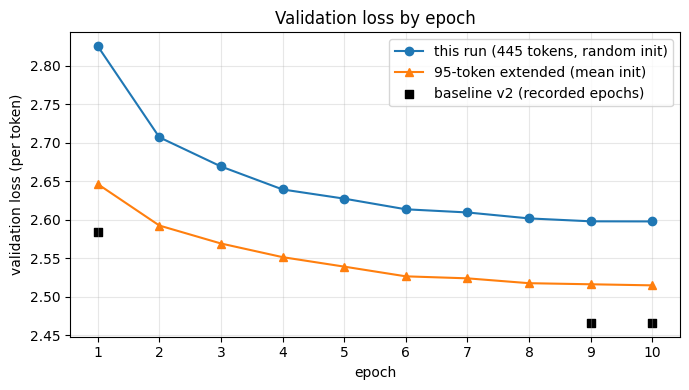

Total skipped updates: 5


In [26]:
# Section 11.1: history table, comparison plot
import matplotlib.pyplot as plt

hist_df = pd.DataFrame(S["history"])
display(hist_df.round(4))

baseline_v2_val = [2.5847, None, None, None, None, None, None, None, 2.4662, 2.4664]   # only epoch 1, 9 and 10 are recorded here
ext95_val = [2.6463, 2.5925, 2.5692, 2.5515, 2.5392, 2.5266, 2.5240, 2.5177, 2.5163, 2.5149]
epochs_all = list(range(1, 11))

fig, ax = plt.subplots(figsize=(7, 4))
if len(hist_df):
    ax.plot(hist_df["epoch"], hist_df["val_loss"], marker="o", label=f"this run ({N_NEW} tokens, {INIT} init)")
ax.plot(epochs_all, ext95_val, marker="^", label="95-token extended (mean init)")
ax.scatter([e for e, v in zip(epochs_all, baseline_v2_val) if v is not None],
           [v for v in baseline_v2_val if v is not None], marker="s", color="k", label="baseline v2 (recorded epochs)")
ax.set_xlabel("epoch"); ax.set_ylabel("validation loss (per token)"); ax.set_xticks(epochs_all)
ax.grid(alpha=0.3); ax.legend(); ax.set_title("Validation loss by epoch")
fig.tight_layout(); fig.savefig(RUN_DIR / "val_loss_comparison.png", dpi=150); plt.show()
print("Total skipped updates:", S["skipped"])

In [27]:
# Section 11.2: backup (download this zip; it allows resuming or evaluating in a later session)
shutil.make_archive(f"/kaggle/working/{RUN_NAME}_backup", "zip", RUN_DIR.parent, RUN_NAME)
print(f"Backup written: /kaggle/working/{RUN_NAME}_backup.zip (%.1f MB)" % (os.path.getsize(f"/kaggle/working/{RUN_NAME}_backup.zip") / 1e6))

Backup written: /kaggle/working/ext_f20_random_s42_backup.zip (66.2 MB)


## Section 12. Evaluation under the fixed pipeline
The same pipeline as baseline v2: `IndicProcessor` prompts, batch size 8, 4 beams, `max_length=256`, `early_stopping=True`, no sampling. Evaluation sets: the first 300 validation sentences and the full 994-sentence test set (used once, here). The best-validation weights are loaded first. Generated token IDs are kept so that added-token usage can be counted exactly.

In [28]:
# Section 12.1: load the best weights and define generation
best_path = RUN_DIR / "best_trainable.pt"
assert best_path.exists(), "No best_trainable.pt found: train first or attach a finished run."
load_trainable(torch.load(best_path, map_location="cpu"))
lora_model.eval()
print("Loaded best weights (validation loss %.4f)." % S["best_val"])

@torch.inference_mode()
def translate(sources, batch_size=8):
    prompts = [processor.preprocess_batch([s], src_lang=SRC_LANG, tgt_lang=TGT_LANG)[0] for s in sources]
    texts, id_lists = [], []
    for i in range(0, len(prompts), batch_size):
        enc = tok(prompts[i:i + batch_size], padding=True, truncation=True, max_length=MAX_LEN, return_tensors="pt").to(DEVICE)
        gen = lora_model.generate(**enc, max_length=256, num_beams=4, early_stopping=True, do_sample=False)
        for row in gen.cpu().tolist():
            id_lists.append(row); texts.append(decode_generated(row))
    return texts, id_lists

val_src = val_df[SRC_COL].astype(str).str.strip().tolist()[:300]
val_ref = val_df[TGT_COL].astype(str).str.strip().tolist()[:300]
test_src = test_df[SRC_COL].astype(str).str.strip().tolist()
test_ref = test_df[TGT_COL].astype(str).str.strip().tolist()

torch.cuda.empty_cache()
for s, r, h in zip(val_src[:2], val_ref[:2], translate(val_src[:2])[0]):
    print("SRC:", s[:100]); print("REF:", r[:100]); print("HYP:", h[:100]); print()

Loaded best weights (validation loss 2.5980).
SRC: According to Minhaj, Iltutmish re-asserted Delhi's control over Badaun, Awadh, Banaras, and Siwalik 
REF: ᱢᱤᱱᱦᱟᱡ ᱟᱜ ᱠᱟᱛᱷᱟᱛᱮ, ᱤᱞᱛᱩᱫᱢᱤᱥ ᱟᱹᱰᱤᱫᱷᱟᱣ ᱥᱟᱸᱜᱷᱟᱨ ᱨᱮ ᱵᱟᱫᱟᱩᱱ, ᱟᱣᱭᱟᱫᱷ, ᱵᱮᱱᱟᱨᱚᱥ ᱟᱨ ᱥᱤᱵᱟᱞᱤᱠ ᱪᱮᱛᱟᱱ ᱫᱚᱲᱦᱟᱛᱮ ᱫᱤᱞ
HYP: ᱢᱤᱱᱦᱟᱡᱽ ᱟᱜ ᱠᱟᱛᱷᱟ ᱞᱮᱠᱟᱛᱮ, ᱤᱞᱛᱩᱫᱢᱤᱥ ᱫᱚ ᱢᱤᱫ ᱵᱟᱨ ᱥᱟᱸᱜᱷᱟᱨ ᱨᱮ ᱵᱟᱫᱟᱣᱩᱱ, ᱟᱣᱟᱫᱷ, ᱵᱮᱱᱟᱨᱚᱥ ᱟᱨ ᱥᱤᱣᱟᱞᱤᱠ ᱪᱮᱛᱟᱱ ᱨᱮ 

SRC: Building points for money back rewards is also a good incentive.
REF: ᱠᱟᱹᱣᱰᱤ ᱨᱩᱭᱟᱹᱲ ᱨᱮᱭᱟᱜ ᱥᱤᱨᱯᱟᱹ ᱞᱟᱵᱷ ᱞᱟᱹᱜᱤᱫ ᱯᱚᱭᱮᱱᱴ ᱛᱩᱢᱟᱹᱞ ᱠᱚᱨᱟᱣ ᱢᱤᱫᱴᱟᱝ ᱵᱷᱟᱜᱮ ᱩᱫᱜᱟᱹᱣ ᱠᱟᱱᱟ ᱾
HYP: ᱠᱟᱹᱣᱰᱤ ᱨᱩᱣᱟᱹᱲ ᱞᱟᱹᱜᱤᱫ ᱯᱚᱭᱮᱱᱴ ᱵᱮᱱᱟᱣ ᱫᱚ ᱢᱤᱫᱴᱟᱝ ᱵᱷᱟᱜᱮ ᱩᱫᱜᱟᱹᱣ ᱦᱚᱸ ᱠᱟᱱᱟ ᱾



In [29]:
# Section 12.2: generate validation (300) and test (994) predictions
preds, gen_ids = {}, {}
for split, src, ref in [("val300", val_src, val_ref), ("test", test_src, test_ref)]:
    t0 = time.time()
    hyp, ids = translate(src)
    preds[split], gen_ids[split] = hyp, ids
    pd.DataFrame({"source": src, "reference": ref, "prediction": hyp}).to_csv(PRED_DIR / f"{RUN_NAME}_{split}.csv", index=False, encoding="utf-8-sig")
    json.dump(ids, open(PRED_DIR / f"{RUN_NAME}_{split}_generated_ids.json", "w"))
    print(f"{split:7s} done in {(time.time() - t0) / 60:.1f} min")

val300  done in 1.1 min
test    done in 4.0 min


## Section 13. Comparison with baseline v2
Both systems were generated through the same pipeline and scored with the same metric code. Differences are reported as this run minus baseline v2, with paired bootstrap intervals over test sentences (1,000 resamples). The intervals cover test-sentence sampling only, not training randomness: each configuration is a single run, so treat differences below about 0.5 BLEU as unresolved.

In [30]:
# Section 13.1: metric helpers
import sacrebleu

def _has(pattern, text): return re.search(pattern, text) is not None

def summarize(system, split, hyp, ref):
    b = sacrebleu.corpus_bleu(hyp, [ref]); c = sacrebleu.corpus_chrf(hyp, [ref]); t = sacrebleu.corpus_ter(hyp, [ref])
    return {"system": system, "split": split, "n": len(ref), "BLEU": round(b.score, 2), "chrF": round(c.score, 2),
            "TER": round(t.score, 2),
            "word_len_ratio": round(sum(len(h.split()) for h in hyp) / sum(len(r.split()) for r in ref), 3),
            "empty": sum(h == "" for h in hyp)}

def paired_bootstrap(hyp_a, hyp_b, ref, B=1000, seed=0):
    rng = np.random.default_rng(seed); n = len(ref); d_bleu, d_chrf = [], []
    for _ in range(B):
        idx = rng.integers(0, n, n)
        r = [ref[i] for i in idx]; a = [hyp_a[i] for i in idx]; b = [hyp_b[i] for i in idx]
        d_bleu.append(sacrebleu.corpus_bleu(b, [r]).score - sacrebleu.corpus_bleu(a, [r]).score)
        d_chrf.append(sacrebleu.corpus_chrf(b, [r]).score - sacrebleu.corpus_chrf(a, [r]).score)
    return d_bleu, d_chrf

def show_bootstrap(label, hyp_a, hyp_b, ref, B=1000):
    d_bleu, d_chrf = paired_bootstrap(hyp_a, hyp_b, ref, B=B)
    out = {}
    for name, d in [("BLEU", d_bleu), ("chrF", d_chrf)]:
        lo, hi = np.percentile(d, [2.5, 97.5])
        out[name] = (float(np.mean(d)), float(lo), float(hi))
        print(f"{label} | {name}: mean {np.mean(d):+.2f}, 95% interval [{lo:+.2f}, {hi:+.2f}], B better in {100*np.mean(np.array(d) > 0):.1f}% of resamples")
    return out

def locate_file(name):
    hits = glob.glob(f"/kaggle/input/**/{name}", recursive=True) + glob.glob(f"/kaggle/working/**/{name}", recursive=True)
    return hits[0] if hits else None
print("Helpers ready.")

Helpers ready.


In [31]:
# Section 13.2: load the baseline v2 (and optional 95-token) predictions
def load_pred_csv(name, ref):
    path = locate_file(name)
    if path is None:
        return None
    df = pd.read_csv(path, encoding="utf-8-sig")
    hyp = df["prediction"].fillna("").astype(str).str.strip().tolist()
    refs_file = df["reference"].fillna("").astype(str).str.strip().tolist()
    assert refs_file == ref, f"{name}: references differ from this notebook's split"
    print("Loaded", path, "|", len(hyp), "rows")
    return hyp

base_test = load_pred_csv("new_baseline_v2_test.csv", test_ref)
base_val = load_pred_csv("new_baseline_v2_val300.csv", val_ref)
ext95_test = load_pred_csv("extended_fixed_test.csv", test_ref)
if base_test is None:
    print("WARNING: new_baseline_v2_test.csv not found. Attach the baseline v2 predictions dataset to run the comparison.")

Loaded /kaggle/input/datasets/sanjeevanijaiswal/baseline-v2-prediction/new_baseline_v2_test.csv | 994 rows
Loaded /kaggle/input/datasets/sanjeevanijaiswal/baseline-v2-prediction/new_baseline_v2_val300.csv | 300 rows


In [32]:
# Section 13.3: scores, bootstrap and added-token usage
this_name = f"this run ({N_NEW} tokens, {INIT})"
rows = []
for split, ref, base in [("val300", val_ref, base_val), ("test", test_ref, base_test)]:
    if base is not None:
        rows.append(summarize("baseline v2", split, base, ref))
    rows.append(summarize(this_name, split, preds[split], ref))
    if split == "test" and ext95_test is not None:
        rows.append(summarize("95-token extended (mean)", split, ext95_test, ref))
score_table = pd.DataFrame(rows)
display(score_table)
score_table.to_csv(RUN_DIR / "scores.csv", index=False)

# usage of the added tokens, counted from the generated IDs
test_has_added = np.array([any(t >= BASE_TARGET_VOCAB_SIZE for t in ids) for ids in gen_ids["test"]])
used_ids = Counter(t for ids in gen_ids["test"] for t in ids if t >= BASE_TARGET_VOCAB_SIZE)
usage = {"test_sentences_using_an_added_token": int(test_has_added.sum()), "added_token_occurrences": int(sum(used_ids.values())),
         "distinct_added_tokens_used": len(used_ids), "added_tokens_available": N_NEW}
print("\nAdded-token usage on the test set:", usage)

summary = {"run": RUN_NAME, "MIN_FREQ": MIN_FREQ, "INIT": INIT, "SEED": SEED, "N_NEW": N_NEW, "best_val_loss": S["best_val"],
           "epochs": len(S["history"]), **usage, **stats}
if base_test is not None:
    print("\nPaired bootstrap on the test set (this run minus baseline v2):")
    bs = show_bootstrap("this run minus baseline v2", base_test, preds["test"], test_ref)
    summary.update({"test_BLEU": float(sacrebleu.corpus_bleu(preds["test"], [test_ref]).score),
                    "test_chrF": float(sacrebleu.corpus_chrf(preds["test"], [test_ref]).score),
                    "baseline_test_BLEU": float(sacrebleu.corpus_bleu(base_test, [test_ref]).score),
                    "baseline_test_chrF": float(sacrebleu.corpus_chrf(base_test, [test_ref]).score),
                    "dBLEU_mean": bs["BLEU"][0], "dBLEU_lo": bs["BLEU"][1], "dBLEU_hi": bs["BLEU"][2],
                    "dchrF_mean": bs["chrF"][0], "dchrF_lo": bs["chrF"][1], "dchrF_hi": bs["chrF"][2]})
    if base_val is not None:
        print("\nPaired bootstrap on the 300 validation sentences:")
        show_bootstrap("this run minus baseline v2 [val300]", base_val, preds["val300"], val_ref)
json.dump(summary, open(RUN_DIR / "run_summary.json", "w"), indent=2)

,system,split,n,BLEU,chrF,TER,word_len_ratio,empty
0,baseline v2,val300,300,12.91,44.89,71.63,1.006,0
1,"this run (445 tokens, random)",val300,300,12.86,45.35,72.61,1.032,0
2,baseline v2,test,994,12.32,45.26,76.99,1.071,0
3,"this run (445 tokens, random)",test,994,12.76,46.04,75.11,1.064,1



Added-token usage on the test set: {'test_sentences_using_an_added_token': 452, 'added_token_occurrences': 776, 'distinct_added_tokens_used': 246, 'added_tokens_available': 445}

Paired bootstrap on the test set (this run minus baseline v2):
this run minus baseline v2 | BLEU: mean +0.43, 95% interval [-0.12, +1.02], B better in 92.6% of resamples
this run minus baseline v2 | chrF: mean +0.78, 95% interval [+0.31, +1.26], B better in 100.0% of resamples

Paired bootstrap on the 300 validation sentences:
this run minus baseline v2 [val300] | BLEU: mean -0.04, 95% interval [-0.74, +0.60], B better in 45.1% of resamples
this run minus baseline v2 [val300] | chrF: mean +0.47, 95% interval [-0.21, +1.09], B better in 90.8% of resamples


In [33]:
# Section 13.4: where does any difference come from?
if base_test is None:
    print("Skipped: needs the baseline v2 predictions.")
else:
    ref_has_added = np.array([added_pattern.search(r) is not None for r in test_ref])
    def delta(idx, other):
        r = [test_ref[i] for i in idx]; b = [other[i] for i in idx]; e = [preds["test"][i] for i in idx]
        return (round(sacrebleu.corpus_bleu(e, [r]).score - sacrebleu.corpus_bleu(b, [r]).score, 2),
                round(sacrebleu.corpus_chrf(e, [r]).score - sacrebleu.corpus_chrf(b, [r]).score, 2))
    rows = []
    for label, mask in [("all", np.ones(len(test_ref), dtype=bool)),
                        ("output uses an added token", test_has_added),
                        ("output uses NO added token", ~test_has_added),
                        ("reference contains an added word", ref_has_added),
                        ("reference contains NO added word", ~ref_has_added)]:
        idx = np.where(mask)[0]
        d_b, d_c = delta(idx, base_test)
        rows.append({"subset": label, "n": len(idx), "dBLEU (run - baseline v2)": d_b, "dchrF (run - baseline v2)": d_c})
    display(pd.DataFrame(rows))
    pd.DataFrame(rows).to_csv(RUN_DIR / "subset_analysis.csv", index=False)
    print("A gain concentrated in the 'uses an added token' subsets would support the extension; a similar change everywhere would not.")

,subset,n,dBLEU (run - baseline v2),dchrF (run - baseline v2)
0,all,994,0.43,0.78
1,output uses an added token,452,0.94,1.57
2,output uses NO added token,542,-0.07,0.01
3,reference contains an added word,576,0.46,0.91
4,reference contains NO added word,418,0.41,0.55


A gain concentrated in the 'uses an added token' subsets would support the extension; a similar change everywhere would not.


In [34]:
# Section 13.5: examples (first 5 test sentences)
for i in range(5):
    print(f"[{i}] SRC : {test_src[i][:110]}")
    print(f"    REF : {test_ref[i][:110]}")
    if base_test is not None:
        print(f"    BASE: {base_test[i][:110]}")
    print(f"    RUN : {preds['test'][i][:110]}\n")

[0] SRC : Puducherry is one of the most popular tourist spots in India for national and international tourists.
    REF : ᱡᱟᱹᱛᱤᱭᱟᱨᱤ ᱟᱨ ᱡᱮᱜᱮᱫ ᱡᱟᱠᱟᱫ ᱥᱟᱸᱜᱷᱟᱨᱤᱭᱟᱹ ᱠᱚᱴᱷᱮᱱ ᱯᱩᱫᱩᱪᱮᱨᱤ ᱫᱚ ᱦᱩᱭᱩᱜ ᱠᱟᱱᱟ ᱵᱷᱟᱨᱚᱛ ᱨᱮᱭᱟᱜ ᱥᱚᱨᱮᱥ ᱧᱩᱢᱡᱚᱝ ᱥᱟᱸᱜᱷᱟᱨ ᱴᱷᱟᱣ ᱾
    BASE: ᱯᱩᱫᱩᱪᱮᱨᱤ ᱵᱷᱟᱨᱚᱛ ᱨᱮᱭᱟᱜ ᱡᱟᱹᱛᱤᱭᱟᱹᱨᱤ ᱟᱨ ᱡᱮᱜᱮᱫ ᱡᱟᱠᱟᱛ ᱥᱟᱸᱜᱷᱟᱨᱤᱭᱟᱹ ᱠᱚ ᱞᱟᱹᱜᱤᱫ ᱡᱚᱛᱚ ᱠᱷᱚᱱ ᱦᱚᱲ ᱠᱩᱥᱤ ᱥᱟᱸᱜᱷᱟᱨ ᱴᱷᱟᱶ ᱠᱚ ᱢᱩᱫᱨᱮ
    RUN : ᱯᱩᱫᱩᱪᱮᱨᱤ ᱵᱷᱟᱨᱚᱛ ᱨᱮᱭᱟᱜ ᱡᱟᱹᱛᱤᱭᱟᱹᱨᱤ ᱟᱨ ᱡᱮᱜᱮᱫ ᱡᱟᱠᱟᱛ ᱥᱟᱸᱜᱷᱟᱨᱤᱭᱟᱹ ᱠᱚ ᱞᱟᱹᱜᱤᱫ ᱥᱚᱨᱮᱥ ᱦᱚᱲ ᱠᱩᱥᱤ ᱥᱟᱸᱜᱷᱟᱨ ᱴᱷᱟᱶ ᱠᱟᱱᱟ ᱾

[1] SRC : She is widely regarded in modern Indian historiography as exemplifying both Akbar's and the Mughals' tolerance
    REF : ᱱᱟᱦᱟᱜ ᱵᱷᱟᱨᱚᱛᱤᱭᱚ ᱱᱟᱜᱟᱢ ᱚᱞ ᱨᱮ ᱩᱱᱤ ᱫᱚ ᱟᱹᱰᱤ ᱛᱮᱫ ᱜᱮ ᱟᱠᱵᱚᱨ ᱟᱨ ᱢᱩᱜᱷᱚᱞ ᱫᱮᱱᱮ ᱵᱟᱱᱟᱨ ᱫᱷᱚᱨᱚᱢᱟᱱᱟᱜ ᱵᱷᱮᱜᱮᱫ ᱨᱮᱱᱟᱜ ᱥᱟᱦᱟᱣᱫᱟᱲᱮ ᱟᱨ
    BASE: ᱩᱱᱤ ᱫᱚ ᱱᱟᱦᱟᱜ ᱵᱷᱟᱨᱚᱛ ᱨᱮᱭᱟᱜ ᱱᱟᱜᱟᱢ ᱪᱤᱛᱟᱹᱨ ᱨᱮ ᱟᱠᱵᱚᱨ ᱟᱨ ᱢᱩᱜᱷᱚᱞ ᱵᱟᱱᱟᱨ ᱫᱷᱚᱨᱚᱢᱟᱱ ᱵᱷᱮᱯᱮᱜᱮᱫ ᱠᱚ ᱥᱟᱦᱟᱣ ᱞᱮᱫᱟ ᱟᱨ ᱢᱤᱫ ᱯᱟᱥᱱᱟᱣ 
    RUN : ᱩᱱᱤ ᱫᱚ ᱱᱟᱦᱟᱜ ᱵᱷᱟᱨᱚᱛ ᱨᱮᱭᱟᱜ ᱱᱟᱜᱟᱢ ᱪᱤᱛᱟᱹᱨ ᱨᱮ ᱟᱠᱵᱚᱨ ᱟᱨ ᱢᱩᱜᱷᱚᱞ ᱵᱟᱱᱟᱦᱚᱲᱟᱜ ᱫᱷᱚᱨᱚᱢᱟᱱ ᱵᱷᱮᱯᱮᱜᱮᱫ ᱟᱨ ᱟᱭᱢᱟ ᱡᱟᱹᱛᱤ ᱟᱨ ᱟᱭᱢᱟ ᱫᱷ

[2] SRC : This way, the Robo advisor can go from

## Section 14. Save everything
Download `results.zip` before the session ends. Send me the epoch lines from Section 10 and the outputs of Sections 6.3, 13.3 and 13.4. Keep each run's `run_summary.json`: once several configurations are done, they combine into the dose-response table.

In [35]:
# Section 14.1: final results bundle (excludes the large checkpoint file)
shutil.make_archive(f"/kaggle/working/{RUN_NAME}_results", "zip", RUN_DIR.parent, RUN_NAME)
print(f"Results bundle: /kaggle/working/{RUN_NAME}_results.zip (%.1f MB)" % (os.path.getsize(f"/kaggle/working/{RUN_NAME}_results.zip") / 1e6))
for p in sorted(RUN_DIR.rglob("*")):
    if p.is_file() and p.name != "latest.pt":
        print(" -", p.relative_to(RUN_DIR), f"({p.stat().st_size/1024:.1f} KB)")

Results bundle: /kaggle/working/ext_f20_random_s42_results.zip (66.2 MB)
 - best_trainable.pt (17462.0 KB)
 - predictions/ext_f20_random_s42_test.csv (666.0 KB)
 - predictions/ext_f20_random_s42_test_generated_ids.json (264.0 KB)
 - predictions/ext_f20_random_s42_val300.csv (190.9 KB)
 - predictions/ext_f20_random_s42_val300_generated_ids.json (72.6 KB)
 - run_summary.json (1.0 KB)
 - scores.csv (0.3 KB)
 - subset_analysis.csv (0.2 KB)
 - tokenization_stats.json (0.3 KB)
 - training_history.json (3.5 KB)
 - val_loss_comparison.png (68.7 KB)
